# 06. IPCA e Política Monetária

## Parte 0 · A Inflação Responde aos Juros?

Os notebooks anteriores responderam perguntas fundamentais sobre a inflação brasileira.

- 02.ipca $\quad\to$ Quanto foi a inflação?
- 02.01 → 02.04 $\quad\to$ Onde ocorreram os movimentos?
- 03.ipca_decomposicao $\quad\to$ A decomposição é consistente?
- 04.ipca_dinamica_inflacionaria $\quad\to$ Qual é a natureza do processo inflacionário?
- 05.ipca_blocos_macro $\quad\to$ De onde economicamente vem a inflação?


Neste notebook mudamos novamente a pergunta.  
Não queremos mais apenas descrever a inflação.  
Também não queremos ainda construir modelos preditivos.

O objetivo agora é compreender a interação entre inflação e política monetária.

- **A pergunta central é**:
    - > A inflação brasileira responde à taxa SELIC?


- **Em teoria, o mecanismo é relativamente simples**:
    - Banco Central eleva a SELIC
    - $\qquad\downarrow$
    - Crédito fica mais caro
    - $\qquad\downarrow$
    - Consumo desacelera
    - $\qquad\downarrow$
    - Investimento desacelera
    - $\qquad\downarrow$
    - Pressões inflacionárias diminuem


Entretanto, a economia real é muito mais complexa.  
A mudança da taxa de juros não afeta a inflação imediatamente.
- Existem defasagens.
- Existem diferenças entre setores.
- Existem períodos nos quais a inflação parece responder fortemente aos juros  
    e outros nos quais a correlação parece praticamente inexistente.

Além disso, existe um importante problema de simultaneidade:

- SELIC influencia inflação  
- $\qquad\downarrow\qquad\uparrow$  
- inflação também influencia SELIC

Afinal, o Banco Central reage justamente ao comportamento esperado da inflação.



## Objetivos

Ao final deste notebook devemos ser capazes de responder:

1. Qual é a correlação entre IPCA e SELIC?

2. A relação muda quando introduzimos defasagens?

3. Existe evidência de transmissão monetária?

4. Qual parece ser o horizonte temporal mais relevante?

5. Existem regimes monetários distintos?

6. Quais lições podem ser aproveitadas para construção das features
   do próximo notebook?


Este notebook funciona como uma ponte entre:
- Análise Econômica
    - $\quad\downarrow$
- Feature Engineering
    - $\quad\downarrow$
- Modelagem Preditiva



# 1. Configuração do Ambiente

In [1]:
from pathlib import Path
import sys

import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

# 2. Importações

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import text
from src.database.connection import engine

## Padronização Visual

Mantemos um padrão único de visualização ao longo de todos os notebooks
analíticos do projeto.

In [3]:
plt.style.use("default")

sns.set_theme(
    style="whitegrid",
    context="talk",
)

plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["xtick.labelsize"] = 11
plt.rcParams["ytick.labelsize"] = 11
plt.rcParams["legend.fontsize"] = 10



# 3. Carregar Dados do PostgreSQL

Utilizaremos apenas séries já persistidas no banco.

Neste notebook trabalharemos com:

```text
IPCA Geral
SELIC Meta
SELIC Over
```

O IPCA representa a inflação observada.

A SELIC representa o instrumento principal da política monetária.


## 3.1 Carregar IPCA Geral

In [4]:
query_ipca = """
    SELECT *
    FROM bcb.ipca_geral
    ORDER BY date
"""

ipca = pd.read_sql(query_ipca, engine)
ipca.tail()

,date,indice,acumulado,acumulado12m,nindice,created_at
557,2026-05-01,0.58,3.20,4.72,7640.15,2026-10-26 14:52:50.227749
558,2026-06-01,0.16,3.36,4.64,7652.37,2026-10-26 14:52:50.227749
559,2026-07-01,0.07,3.44,4.44,7657.73,2026-10-26 14:52:50.227749
560,2026-08-01,-0.32,3.11,4.22,7633.23,2026-10-26 14:52:50.227749
561,2026-09-01,0.82,3.95,4.58,7695.82,2026-10-26 14:52:50.227749


## 3.2 Carregar SELIC Meta

In [5]:
query_selic_meta = """
    SELECT *
    FROM bcb.selic_meta
    ORDER BY date
"""

selic_meta = pd.read_sql(query_selic_meta, engine)
selic_meta.tail()

,date,value,series_id,created_at,updated_at
9800,2026-10-31,13.75,432,2026-10-26 15:07:03.307811,2026-10-26 15:07:03.307811
9801,2026-11-01,13.75,432,2026-10-26 15:07:03.307811,2026-10-26 15:07:03.307811
9802,2026-11-02,13.75,432,2026-10-26 15:07:03.307811,2026-10-26 15:07:03.307811
9803,2026-11-03,13.75,432,2026-10-26 15:07:03.307811,2026-10-26 15:07:03.307811
9804,2026-11-04,13.75,432,2026-10-26 15:07:03.307811,2026-10-26 15:07:03.307811


## 3.3 Carregar SELIC Over

In [6]:
query_selic_over = """
    SELECT *
    FROM bcb.selic_over
    ORDER BY date
"""

selic_over = pd.read_sql(query_selic_over, engine)
selic_over.tail()

,date,value,series_id,created_at,updated_at
6729,2026-10-19,0.050788,11,2026-10-26 15:08:40.696194,2026-10-26 15:08:40.696194
6730,2026-10-20,0.050788,11,2026-10-26 15:08:40.696194,2026-10-26 15:08:40.696194
6731,2026-10-21,0.050788,11,2026-10-26 15:08:40.696194,2026-10-26 15:08:40.696194
6732,2026-10-22,0.050788,11,2026-10-26 15:08:40.696194,2026-10-26 15:08:40.696194
6733,2026-10-23,0.050788,11,2026-10-26 15:08:40.696194,2026-10-26 15:08:40.696194


# 4. Preparação dos Dados

Antes de qualquer análise econômica precisamos garantir
consistência temporal entre as séries.

Como inflação e juros possuem frequências distintas em muitas bases,
uma etapa importante consiste em harmonizar a granularidade temporal.

Como as séries já se encontram estruturadas pelo projeto,
esta etapa é relativamente simples.

## 4.1 Datas

In [7]:
ipca["date"] = pd.to_datetime(ipca["date"])
selic_meta["date"] = pd.to_datetime(selic_meta["date"])
selic_over["date"] = pd.to_datetime(selic_over["date"])

## 4.2 Ordenação

In [8]:
ipca = ipca.sort_values("date").reset_index(drop=True)
selic_meta = selic_meta.sort_values("date").reset_index(drop=True)
selic_over = selic_over.sort_values("date").reset_index(drop=True)


## 4.3 Cobertura Individual

In [9]:
cobertura = pd.DataFrame({
    "serie": ["IPCA", "SELIC Meta", "SELIC Over"],
    "frequencia": ["Mensal", "Diária", "Diária"],
    "inicio": [
        ipca["date"].min(),
        selic_meta["date"].min(),
        selic_over["date"].min()
    ],
    "fim": [
        ipca["date"].max(),
        selic_meta["date"].max(),
        selic_over["date"].max()
    ],
    "observacoes": [
        len(ipca),
        len(selic_meta),
        len(selic_over)
    ]
})

cobertura

,serie,frequencia,inicio,fim,observacoes
0,IPCA,Mensal,1979-12-01,2026-09-01,562
1,SELIC Meta,Diária,2000-01-01,2026-11-04,9805
2,SELIC Over,Diária,2000-01-03,2026-10-23,6734


A tabela acima identifica o período efetivamente disponível em cada série.

Como o objetivo é comparar inflação e juros,
trabalharemos posteriormente apenas com a interseção temporal válida.

# 5. Construção da Base Analítica

Agora construiremos uma única base contendo inflação e juros.

Essa base servirá como referência para todas as análises do notebook.

## 5.1 Selecionar Variáveis

In [10]:
ipca_base = ipca[["date", "indice", "acumulado12m"]].copy()

# FREQUÊNCIA MENSAL
selic_meta_mensal = (
    selic_meta
    .set_index("date")
    .resample("MS")
    .mean(numeric_only=True)
    .reset_index()
)
selic_over_mensal = (
    selic_over
    .set_index("date")
    .resample("MS")
    .mean(numeric_only=True)
    .reset_index()
)

selic_meta_base = selic_meta_mensal[["date", "value"]].copy()
selic_over_base = selic_over_mensal[["date", "value"]].copy()

## 5.2 Renomear Campos

A nomenclatura explícita facilita a interpretação ao longo do notebook.

In [11]:
selic_meta_base = selic_meta_base.rename(
    columns={selic_meta_base.columns[-1]: "selic_meta"}
)

selic_over_base = selic_over_base.rename(
    columns={selic_over_base.columns[-1]: "selic_over"}
)

## 5.3 Integrar Séries

In [12]:
base = (
    ipca_base
    .merge(
        selic_meta_base[["date", "selic_meta"]],
        on="date",
        how="inner"
    )
    .merge(
        selic_over_base[["date", "selic_over"]],
        on="date",
        how="inner"
    )
)

base.tail(80)

,date,indice,acumulado12m,selic_meta,selic_over
241,2020-02-01,0.25,4.01,4.293103,0.016296
242,2020-03-01,0.07,3.30,4.040323,0.015356
243,2020-04-01,-0.31,2.40,3.750000,0.014227
244,2020-05-01,-0.38,1.88,3.145161,0.011777
245,2020-06-01,0.26,2.13,2.675000,0.010101
...,...,...,...,...,...
316,2026-05-01,0.58,4.72,14.500000,0.053400
317,2026-06-01,0.16,4.64,14.391667,0.053028
318,2026-07-01,0.07,4.44,14.250000,0.052531
319,2026-08-01,-0.32,4.22,14.040323,0.051784


## 5.4 Verificação de Valores Nulos

In [13]:
base.isna().sum()

date            0
indice          0
acumulado12m    0
selic_meta      0
selic_over      0
dtype: int64

## 5.5 Estrutura Final

In [14]:
base.info()

<class 'pandas.DataFrame'>
RangeIndex: 321 entries, 0 to 320
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype        
---  ------        --------------  -----        
 0   date          321 non-null    datetime64[s]
 1   indice        321 non-null    float64      
 2   acumulado12m  321 non-null    float64      
 3   selic_meta    321 non-null    float64      
 4   selic_over    321 non-null    float64      
dtypes: datetime64[s](1), float64(4)
memory usage: 12.7 KB


A base analítica contém:

- date
- indice
- acumulado12m
- selic_meta
- selic_over

Essa estrutura será suficiente para todas as análises
desta primeira etapa do notebook.

# 6. Cobertura Histórica Consolidada

In [15]:
print("Início:", base["date"].min())
print("Fim:", base["date"].max())
print("Observações:", len(base))

Início: 2000-01-01 00:00:00
Fim: 2026-09-01 00:00:00
Observações: 321


## Interpretação

A cobertura efetiva da base representa o período no qual
inflação e juros estão simultaneamente disponíveis.

Esse ponto é extremamente importante.

Correlações calculadas em janelas diferentes podem produzir
resultados completamente distintos.

Ao trabalhar apenas com a interseção comum evitamos distorções
causadas por períodos faltantes.

# 7. Observações Mais Recentes

In [16]:
base.tail(12)

,date,indice,acumulado12m,selic_meta,selic_over
309,2025-10-01,0.09,4.68,15.000000,0.055131
310,2025-11-01,0.18,4.46,15.000000,0.055131
311,2025-12-01,0.33,4.26,15.000000,0.055131
312,2026-01-01,0.33,4.44,15.000000,0.055131
313,2026-02-01,0.70,3.81,15.000000,0.055131
314,2026-03-01,0.88,4.14,14.895161,0.054777
315,2026-04-01,0.67,4.39,14.741667,0.054223
316,2026-05-01,0.58,4.72,14.500000,0.053400
317,2026-06-01,0.16,4.64,14.391667,0.053028
318,2026-07-01,0.07,4.44,14.250000,0.052531


As observações mais recentes permitem verificar se os dados utilizados
estão atualizados e coerentes com a realidade econômica recente.

Antes de avançar para análises mais sofisticadas,
sempre é recomendável inspecionar os dados observados.

# 8. Estatísticas Descritivas

In [17]:
base[
    [
        "indice",
        "acumulado12m",
        "selic_meta",
        "selic_over"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
indice,321.0,0.493520,0.393600,-0.680000,0.250000,0.450000,0.670000,3.020000
acumulado12m,321.0,6.181277,2.676980,1.880000,4.460000,5.790000,7.180000,17.240000
selic_meta,321.0,12.439115,4.844338,2.000000,9.250000,12.338710,15.000000,26.500000
selic_over,321.0,0.045854,0.017116,0.007469,0.034749,0.045879,0.055131,0.092758


## Leitura Econômica Inicial

Antes mesmo de calcular correlações já podemos obter informações importantes.

As estatísticas descritivas permitem identificar:

- médias históricas;
- dispersão;
- amplitudes;
- extremos observados;
- diferenças entre inflação e juros.

Em diversos episódios da história econômica brasileira,
a SELIC precisou atingir níveis muito elevados para tentar ancorar
expectativas inflacionárias.

A análise visual dessas trajetórias será o próximo passo.

Na próxima parte iniciaremos o estudo conjunto da evolução
histórica de inflação e juros.


---

# PARTE II · EVOLUÇÃO CONJUNTA DE IPCA E SELIC

A partir deste ponto iniciaremos:

- séries históricas;
- normalização;
- comparação visual;
- correlação contemporânea.


# PARTE II · EVOLUÇÃO CONJUNTA DE IPCA E SELIC

Até este ponto construímos uma base integrada contendo inflação
e juros.

Antes de partir para correlações e defasagens,
é importante observar a evolução histórica das séries.

Uma inspeção visual frequentemente revela informações que
não aparecem imediatamente em estatísticas resumidas.

Queremos responder:

- quando ocorreram os maiores ciclos inflacionários?
- quando ocorreram os maiores apertos monetários?
- inflação e juros parecem caminhar juntos?
- existem períodos claramente distintos?


# 9. Evolução Histórica do IPCA

## 9.1 Inflação Mensal

O IPCA mensal representa o movimento inflacionário observado
em cada mês.

Trata-se da medida mais volátil da inflação.

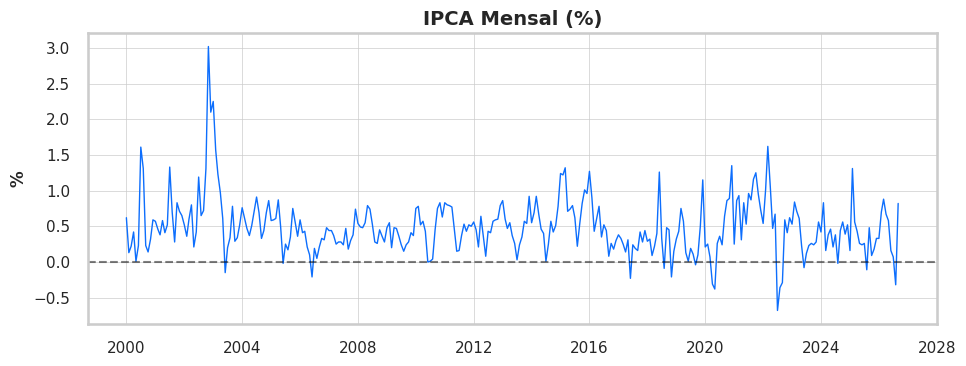

In [18]:
fig, ax = plt.subplots()

ax.plot(
    base["date"],
    base["indice"],
    color="#0d6efd",
    linewidth=1,
)
ax.axhline(
    y=0,
    color="black",
    linestyle="--",
    linewidth=1.5,
    alpha=0.5
)
ax.set_title("IPCA Mensal (%)")
ax.set_ylabel("%")
ax.set_xlabel("")

plt.tight_layout()
plt.show()

### Leitura Econômica

A inflação mensal é naturalmente ruidosa.

Muitos choques afetam os preços em horizontes curtos:

- alimentos;
- energia;
- combustíveis;
- câmbio;
- eventos climáticos;
- preços administrados.

Por esse motivo,
bancos centrais normalmente observam janelas mais longas
antes de alterar significativamente a política monetária.


## 9.2 IPCA Acumulado em 12 Meses

A inflação acumulada em 12 meses suaviza movimentos temporários
e permite identificar regimes inflacionários com maior clareza.

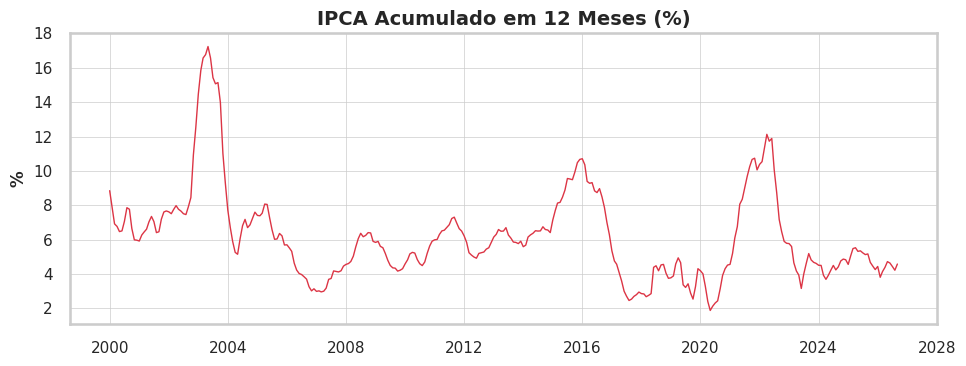

In [19]:
fig, ax = plt.subplots()

ax.plot(
    base["date"],
    base["acumulado12m"],
    color="#dc3545",
    linewidth=1
)
ax.set_title("IPCA Acumulado em 12 Meses (%)")
ax.set_ylabel("%")
ax.set_xlabel("")

plt.tight_layout()
plt.show()

### Leitura Econômica

A inflação acumulada em 12 meses representa uma medida muito mais
próxima daquilo que formuladores de política econômica observam.

Quando essa série acelera persistentemente,
aumenta a probabilidade de aperto monetário.

Quando desacelera,
aumenta o espaço para flexibilização da política monetária.


# 10. Evolução Histórica da SELIC

## 10.1 SELIC Meta

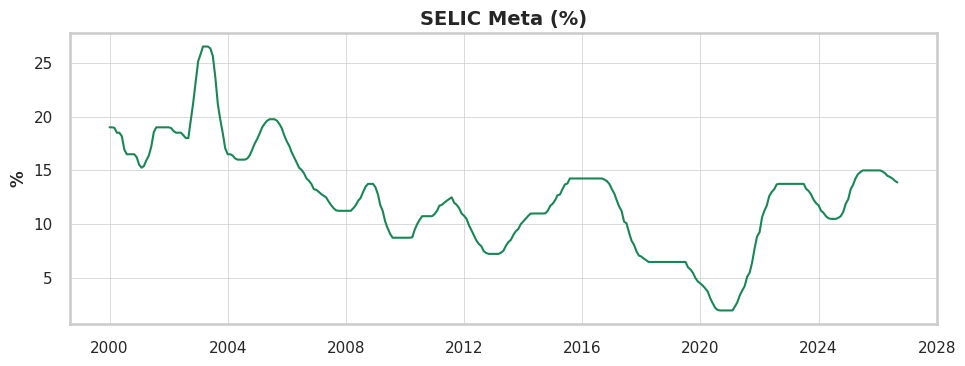

In [20]:
fig, ax = plt.subplots()

ax.plot(
    base["date"],
    base["selic_meta"],
    color="#198754",
    linewidth=1.5
)

ax.set_title("SELIC Meta (%)")
ax.set_ylabel("%")
ax.set_xlabel("")

plt.tight_layout()
plt.show()

### O que observamos?

A SELIC não é uma variável de mercado.

Ela representa uma decisão de política monetária.

Diferentemente do IPCA,
suas mudanças tendem a ocorrer em degraus.

Isso ocorre porque alterações na taxa básica de juros
dependem das decisões do Comitê de Política Monetária.


## 10.2 SELIC Over

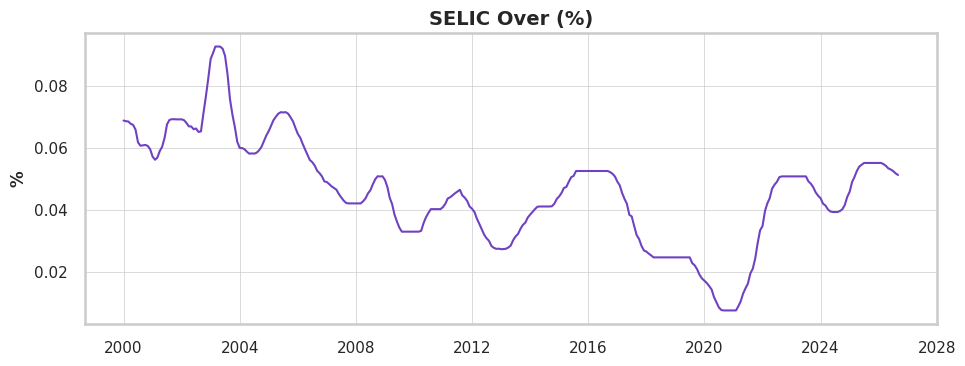

In [21]:
fig, ax = plt.subplots()

ax.plot(
    base["date"],
    base["selic_over"],
    color="#6f42c1",
    linewidth=1.5
)

ax.set_title("SELIC Over (%)")
ax.set_ylabel("%")
ax.set_xlabel("")

plt.tight_layout()
plt.show()

## 10.3 IPCA 12m x SELIC Meta


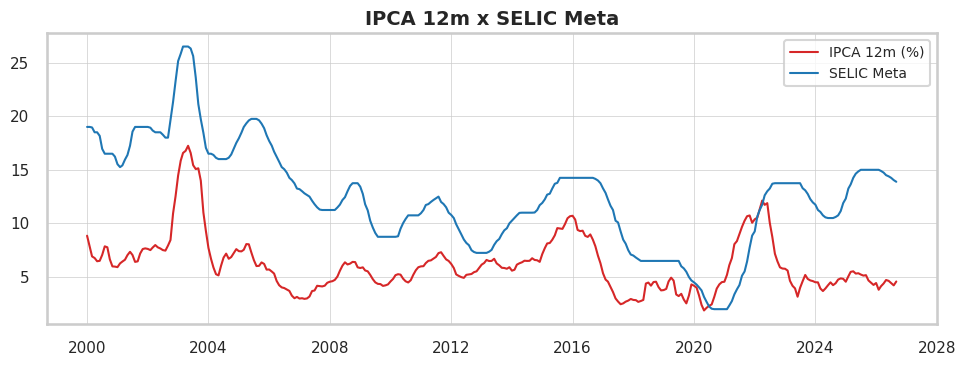

In [22]:
fig, ax1 = plt.subplots()

ax1.plot(
    base["date"],
    base["acumulado12m"],
    color="#d62728",
    linewidth=1.5,
    label="IPCA 12m (%)"
)
ax1.plot(
    base["date"],
    base["selic_meta"],
    color="#1f77b4",
    linewidth=1.5,
    label="SELIC Meta"
)
ax1.set_title("IPCA 12m x SELIC Meta")
ax1.legend()

plt.tight_layout()
plt.show()

Em condições normais,
a SELIC Over acompanha de forma próxima a taxa meta.

Diferenças pequenas são esperadas devido às condições
do mercado monetário.


# 11. Comparação Direta entre Inflação e Juros

A simples comparação das séries originais pode ser difícil,
pois elas possuem magnitudes distintas.

Uma alternativa consiste em normalizar as séries.

## 11.1 Normalização Base 100

In [23]:
base_norm = base.copy()

for coluna in ["acumulado12m","selic_meta",]:
    valor_inicial = base_norm[coluna].iloc[0]

    base_norm[coluna] = (
        base_norm[coluna] / valor_inicial * 100
    )

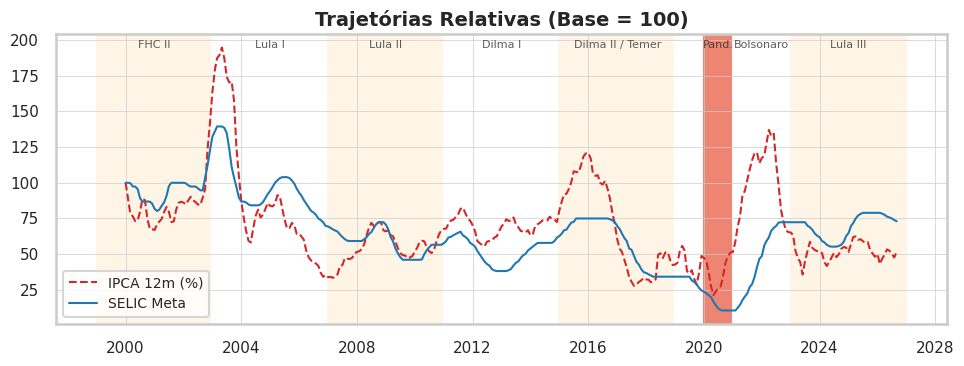

In [24]:
fig, ax = plt.subplots()

governos = [
    ("1999-01-01", "2003-01-01", "FHC II", "#fff5e6"),
    ("2003-01-01", "2007-01-01", "Lula I", "#ffffff"),
    ("2007-01-01", "2011-01-01", "Lula II", "#fff5e6"),
    ("2011-01-01", "2015-01-01", "Dilma I", "#ffffff"),
    ("2015-01-01", "2019-01-01", "Dilma II / Temer", "#fff5e6"),
    ("2019-01-01", "2020-01-01", "", "#ffffff"),
    ("2020-01-01", "2021-01-01", "Pand.", "#ee7e6b6d"),
    ("2021-01-01", "2023-01-01", "Bolsonaro", "#ffffff"),
    ("2023-01-01", "2027-01-01", "Lula III", "#fff5e6"),
]

for inicio, fim, rotulo, cor in governos:
    ax.axvspan(
        pd.Timestamp(inicio),
        pd.Timestamp(fim),
        color=cor,
        alpha=0.95,
        zorder=0,
    )
    meio = (pd.Timestamp(inicio) + (pd.Timestamp(fim) - pd.Timestamp(inicio)) / 2)
    ax.text(
        meio,
        0.98,
        rotulo,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        alpha=0.75,
    )


ax.plot(
    base_norm["date"],
    base_norm["acumulado12m"],
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
    label="IPCA 12m (%)"
)
ax.plot(
    base_norm["date"],
    base_norm["selic_meta"],
    color="#1f77b4",
    linewidth=1.5,
    label="SELIC Meta"
)

ax.legend()
ax.set_title(
    "Trajetórias Relativas (Base = 100)"
)

plt.tight_layout()
plt.show()

### Interpretação

A normalização remove diferenças de escala.

O objetivo não é comparar valores absolutos,
mas sim trajetórias.

Isso permite observar:

- convergências;
- divergências;
- mudanças estruturais;
- grandes ciclos econômicos.


# 12. Janela Recente

Em muitos casos,
os ciclos mais recentes são os mais relevantes
para a formulação de hipóteses econômicas.


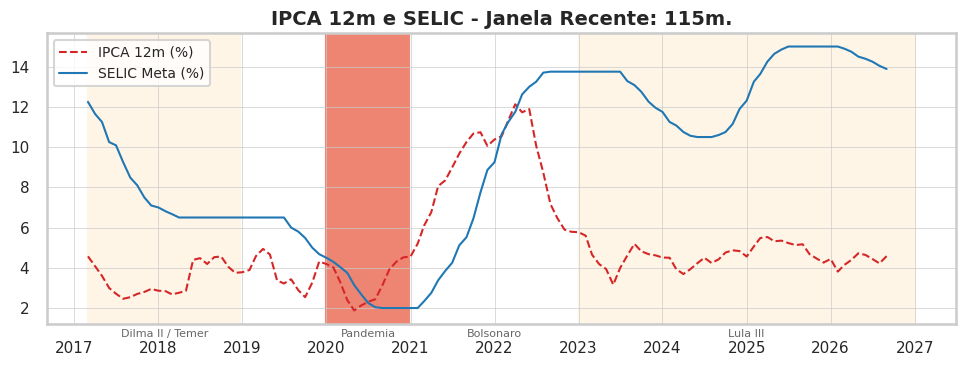

In [25]:
janela = 115
janela_recente = base.tail(janela)

fig, ax1 = plt.subplots()

governos = [
    (min(janela_recente["date"]), "2019-01-01", "Dilma II / Temer", "#fff5e6"),
    ("2019-01-01", "2020-01-01", "", "#ffffff"),
    ("2020-01-01", "2021-01-01", "Pandemia", "#ee7e6b6d"),
    ("2021-01-01", "2023-01-01", "Bolsonaro", "#ffffff"),
    ("2023-01-01", "2027-01-01", "Lula III", "#fff5e6"),
]

for inicio, fim, rotulo, cor in governos:
    ax1.axvspan(
        pd.Timestamp(inicio),
        pd.Timestamp(fim),
        color=cor,
        alpha=0.95,
        zorder=0,
    )
    meio = (pd.Timestamp(inicio) + (pd.Timestamp(fim) - pd.Timestamp(inicio)) / 2)
    ax1.text(
        meio,
        ax1.get_ylim()[1] * 0.98,
        rotulo,
        ha="center",
        va="top",
        fontsize=8,
        alpha=0.7,
    )

ax1.plot(
    janela_recente["date"],
    janela_recente["acumulado12m"],
    color="#d62728",
    linestyle="--",
    linewidth=1.5,
    label="IPCA 12m (%)"
)
ax1.plot(
    janela_recente["date"],
    janela_recente["selic_meta"],
    color="#1f77b4",
    linewidth=1.5,
    label="SELIC Meta (%)"
)
ax1.set_title(f"IPCA 12m e SELIC - Janela Recente: {janela}m.")
ax1.legend()

plt.tight_layout()
plt.show()

O gráfico acima frequentemente fornece uma primeira indicação visual
sobre a condução da política monetária.

Em diversos momentos históricos:

- inflação sobe;
- Banco Central reage;
- juros aumentam;
- inflação desacelera posteriormente.

Contudo,
ainda não sabemos se esse padrão aparece sistematicamente.


# 13. Grandes Ciclos Monetários

Podemos construir uma visão resumida da economia
separando alguns períodos em blocos temporais.

O objetivo não é produzir uma cronologia oficial,
mas sim criar uma leitura macroeconômica da amostra.

In [26]:
base["ano"] = base["date"].dt.year

In [27]:
ciclos = (
    base.groupby("ano").agg(
        ipca_12m=("acumulado12m", "mean"),
        selic_meta=("selic_meta", "mean")
    )
)

ciclos.tail()

,ipca_12m,selic_meta
ano,,
2022,9.341667,12.537442
2023,4.600833,13.299328
2024,4.367500,10.940188
2025,5.019167,14.411559
2026,4.375556,14.522461


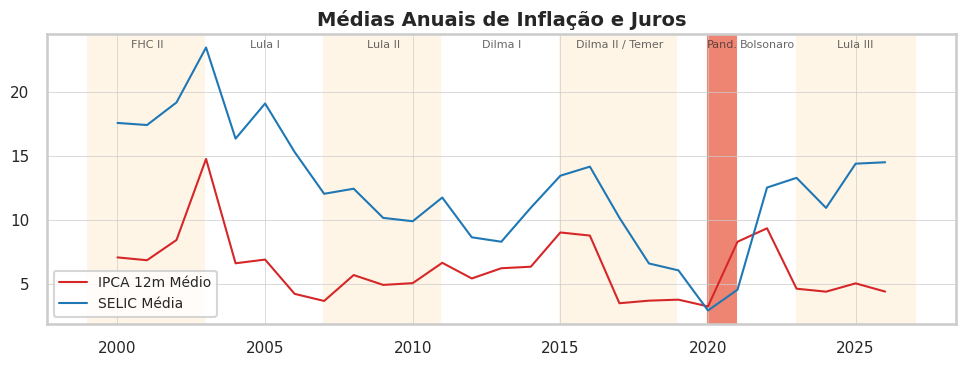

In [28]:
fig, ax = plt.subplots()

governos = [
    (1999, 2003, "FHC II", "#fff5e6"),
    (2003, 2007, "Lula I", "#ffffff"),
    (2007, 2011, "Lula II", "#fff5e6"),
    (2011, 2015, "Dilma I", "#ffffff"),
    (2015, 2019, "Dilma II / Temer", "#fff5e6"),
    (2019, 2020, "", "#ffffff"),
    (2020, 2021, "Pand.", "#ee7e6b"),
    (2021, 2023, "Bolsonaro", "#ffffff"),
    (2023, 2027, "Lula III", "#fff5e6"),
]
for inicio, fim, rotulo, cor in governos:
    ax.axvspan(inicio,fim,color=cor,alpha=0.95,zorder=0,)
    meio = inicio + (fim - inicio) / 2
    ax.text(
        meio,
        0.98,
        rotulo,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="top",
        fontsize=8,
        alpha=0.7,
    )

ax.plot(
    ciclos.index,
    ciclos["ipca_12m"],
    color="#d62728",
    linewidth=1.5,
    label="IPCA 12m Médio"
)
ax.plot(
    ciclos.index,
    ciclos["selic_meta"],
    color="#1f77b4",
    linewidth=1.5,
    label="SELIC Média"
)

ax.legend()
ax.set_title("Médias Anuais de Inflação e Juros")

plt.tight_layout()
plt.show()

A agregação anual reduz ruídos mensais
e facilita a identificação de ciclos econômicos.

Neste nível de agregação já é possível observar:

- períodos de inflação elevada;
- períodos de aperto monetário;
- períodos de estabilidade relativa.


# PARTE III · CORRELAÇÃO CONTEMPORÂNEA

Até agora observamos as séries visualmente.

O próximo passo consiste em medir quantitativamente
a associação entre inflação e juros.

Começaremos pela correlação contemporânea,
isto é:

- $\to\quad$ **IPCA(t) x SELIC(t)**

antes de introduzir defasagens.


## 14. Conceito de Correlação

Correlação mede o grau de associação entre duas variáveis.

Valores próximos de:

```text
+1  → associação positiva forte
 0  → ausência de associação linear
-1  → associação negativa forte
```

Importante:

Correlação não implica causalidade.

Essa ressalva é particularmente relevante em política monetária,
pois inflação e juros influenciam-se mutuamente.


## 15. Correlação de Pearson

In [29]:
corr_pearson_meta = (base["acumulado12m"].corr(base["selic_meta"]))

corr_pearson_over = (base["acumulado12m"].corr(base["selic_over"]))

In [30]:
print(f"Pearson IPCA12m x SELIC Meta: {corr_pearson_meta:.4f}")

print(f"Pearson IPCA12m x SELIC Over: {corr_pearson_over:.4f}")

Pearson IPCA12m x SELIC Meta: 0.5724
Pearson IPCA12m x SELIC Over: 0.5588


## Interpretação

A correlação contemporânea responde apenas uma pergunta:

```text
inflação e juros tendem a se mover juntos?
```

Ela não responde:

```text
quem reage a quem?
```

Isso será estudado posteriormente utilizando defasagens.


## 16. Correlação de Spearman

In [31]:
corr_spearman_meta = (
    base["acumulado12m"].corr(
        base["selic_meta"],method="spearman")
)

corr_spearman_meta

np.float64(0.5051146819258405)

A correlação de Spearman é menos sensível
a valores extremos.

Ela captura relações monotônicas
mesmo quando a relação não é perfeitamente linear.


## 17. Scatter Plot

Uma forma importante de validar correlações
é observar os dados diretamente.

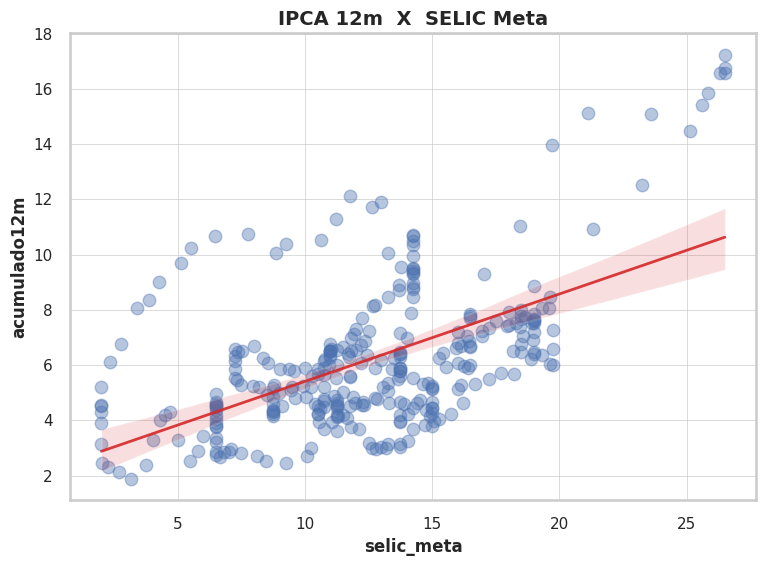

In [32]:
fig, ax = plt.subplots(figsize=(8, 6))

sns.regplot(
    data=base,
    x="selic_meta",
    y="acumulado12m",
    scatter_kws={"alpha": 0.4},
    line_kws={
        "color": "#d62728",
        "linewidth": 2,
        "alpha": 0.9,
    },
    ax=ax
)

ax.set_title("IPCA 12m  X  SELIC Meta")

plt.tight_layout()
plt.show()

## Leitura Econômica Inicial

O gráfico de dispersão permite verificar:

- concentração dos pontos;
- não linearidades;
- outliers;
- possíveis mudanças de regime.

Em muitas economias,
a correlação contemporânea entre inflação e juros
tende a ser positiva.

Isso não significa que juros gerem inflação.

Significa frequentemente que:

- inflação sobe
    - $\downarrow$
- Banco Central reage
    - $\downarrow$
- SELIC sobe

Ou seja,
a correlação contemporânea muitas vezes captura
a reação da autoridade monetária,
e não necessariamente o efeito dos juros sobre a inflação.

Por esse motivo,
a análise das defasagens é essencial.

É exatamente esse o objetivo da próxima parte.


# PARTE IV · CORRELAÇÕES DEFASADAS

A principal limitação da correlação contemporânea é que ela ignora o
tempo necessário para transmissão da política monetária.

Na prática:

- Banco Central sobe a SELIC hoje

    - $\qquad\downarrow$

- Famílias adiam consumo

    - $\qquad\downarrow$

- Empresas reduzem demanda por crédito

    - $\qquad\downarrow$

- Economia desacelera

    - $\qquad\downarrow$

- Inflação responde meses depois


Portanto:

```text
SELIC(t)
não necessariamente afeta
IPCA(t)
```

O efeito relevante pode ocorrer em:

```text
t + 3 meses
t + 6 meses
t + 12 meses
t + 18 meses
```

É exatamente isso que investigaremos agora.


## 18. O Conceito de Defasagem

Uma defasagem representa um deslocamento temporal de uma variável.

Exemplo:

```text
SELIC(t-6)
```

significa:

> SELIC observada seis meses atrás.

Assim conseguimos responder:

> A inflação atual possui maior relação com os juros praticados meses antes?


## 19. Construir Defasagens da SELIC

In [33]:
lags = [
    1,
    3,
    6,
    9,
    12,
    18,
    24
]

In [34]:
for lag in lags:
    base[f"selic_lag_{lag}"] = (base["selic_meta"].shift(lag))

In [35]:
base.filter(regex="selic").tail()

,selic_meta,selic_over,selic_lag_1,selic_lag_3,selic_lag_6,selic_lag_9,selic_lag_12,selic_lag_18,selic_lag_24
316,14.500000,0.053400,14.741667,15.000000,15.000000,15.0,14.637097,11.150000,10.564516
317,14.391667,0.053028,14.500000,14.895161,15.000000,15.0,14.850000,11.895161,10.500000
318,14.250000,0.052531,14.391667,14.741667,15.000000,15.0,15.000000,12.314516,10.500000
319,14.040323,0.051784,14.250000,14.500000,15.000000,15.0,15.000000,13.250000,10.500000
320,13.883333,0.051245,14.040323,14.391667,14.895161,15.0,15.000000,13.637097,10.600000


## Verificação

As primeiras observações naturalmente apresentam valores ausentes.

Isso ocorre porque ainda não existem observações históricas suficientes
para compor a defasagem.

In [36]:
base[[c for c in base.columns if "lag" in c]].isna().sum()

selic_lag_1      1
selic_lag_3      3
selic_lag_6      6
selic_lag_9      9
selic_lag_12    12
selic_lag_18    18
selic_lag_24    24
dtype: int64

- Os valores ausentes observados nas variáveis defasadas são esperados.  
Cada defasagem requer observações históricas anteriores para ser calculada.  
Assim, uma defasagem de 12 meses gera naturalmente 12 observações iniciais sem valor disponível.

# 20. Correlação por Horizonte Temporal

Agora calcularemos:

```text
corr(
    IPCA(t),
    SELIC(t-k)
)
```

para diferentes valores de k.


In [37]:
resultado_lags = []

for lag in lags:
    corr = base["acumulado12m"].corr(base[f"selic_lag_{lag}"])

    resultado_lags.append({
            "lag_meses": lag,
            "correlacao": corr
        }
    )

In [38]:
corr_lags = pd.DataFrame(resultado_lags)

corr_lags

,lag_meses,correlacao
0,1,0.546177
1,3,0.474288
2,6,0.328605
3,9,0.181399
4,12,0.091597
5,18,0.053911
6,24,0.028121


In [39]:
base["ipca_diff"] = (
    base["acumulado12m"]
    .diff()
)



In [40]:
cor2 = base["indice"].corr(
    base["selic_lag_12"]
)

cor2

np.float64(0.02778011134221909)

## Ranking de Defasagens

In [41]:
corr_lags.sort_values("correlacao", ascending=False)

,lag_meses,correlacao
0,1,0.546177
1,3,0.474288
2,6,0.328605
3,9,0.181399
4,12,0.091597
5,18,0.053911
6,24,0.028121


## Interpretação

A tabela acima é uma das mais importantes deste notebook.

Ela permite avaliar se:

- a correlação aumenta após alguns meses;
- a correlação diminui;
- existe um horizonte dominante;
- os efeitos parecem rápidos ou lentos.


## 21. Gráfico das Correlações Defasadas

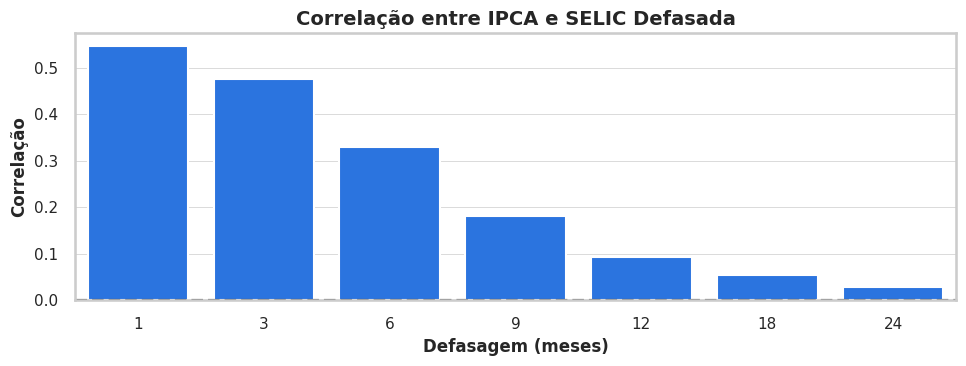

In [42]:
fig, ax = plt.subplots()

sns.barplot(
    data=corr_lags,
    x="lag_meses",
    y="correlacao",
    color="#0d6efd",
    ax=ax
)

ax.axhline(
    0,
    color="black",
    linestyle="--"
)

ax.set_title("Correlação entre IPCA e SELIC Defasada")
ax.set_xlabel("Defasagem (meses)")
ax.set_ylabel("Correlação")

plt.tight_layout()
plt.show()

## Leitura Econômica

Caso as maiores correlações ocorram em horizontes mais longos,
temos uma indicação de que os efeitos monetários não são imediatos.

Isso é compatível com grande parte da literatura macroeconômica,
que normalmente encontra defasagens relevantes entre política monetária
e inflação.


# 22. Heatmap das Correlações

In [43]:
heatmap_df = corr_lags.set_index(
    "lag_meses"
).T

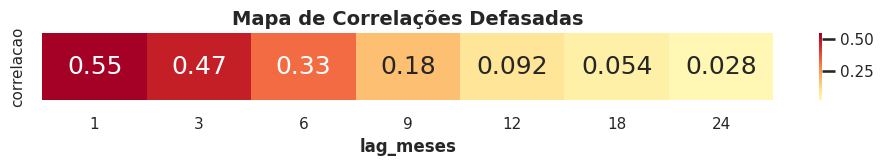

In [44]:
fig, ax = plt.subplots(figsize=(10, 2))

sns.heatmap(
    heatmap_df,
    annot=True,
    cmap="RdYlBu_r",
    center=0,
    ax=ax
)

ax.set_title(
    "Mapa de Correlações Defasadas"
)

plt.tight_layout()
plt.show()

O heatmap facilita a visualização dos horizontes temporais
mais relevantes.

Tons mais intensos indicam relações mais fortes.


## 23. Melhor Defasagem Observada

In [45]:
melhor_lag = (
    corr_lags
    .sort_values(
        "correlacao",
        ascending=False
    )
    .iloc[0]
)

melhor_lag

lag_meses     1.000000
correlacao    0.546177
Name: 0, dtype: float64

In [46]:
print(
    f"Melhor lag observado: "
    f"{int(melhor_lag['lag_meses'])} meses"
)

print(
    f"Correlação: "
    f"{melhor_lag['correlacao']:.4f}"
)

Melhor lag observado: 1 meses
Correlação: 0.5462


## Interpretação Econômica

O horizonte identificado acima representa o ponto em que a SELIC
possui maior associação estatística com a inflação.

Não devemos interpretar esse número como um prazo exato
de transmissão monetária.

Contudo:

ele fornece uma referência extremamente útil para:

- análise econômica;
- construção de features;
- modelagem futura.


# PARTE V · CROSS-CORRELATION

As correlações calculadas anteriormente utilizam apenas
alguns horizontes específicos.

Podemos expandir a análise observando uma faixa contínua
de defasagens.

Essa técnica é conhecida como:

```text
Cross-Correlation
```

e permite mapear toda a estrutura temporal
da relação entre juros e inflação.


## 24. O que é Cross-Correlation?

A função de correlação cruzada calcula:

```text
corr(
    IPCA(t),
    SELIC(t-k)
)
```

para muitos valores de k.

Isso produz uma curva completa de correlações.

Em vez de analisar alguns pontos específicos,
observamos toda a estrutura temporal simultaneamente.


## 25. Calcular Cross-Correlation

In [47]:
max_lag = 36

In [48]:
cross_corr = []

for lag in range(max_lag + 1):

    corr = (
        base["acumulado12m"]
        .corr(
            base["selic_meta"].shift(lag)
        )
    )

    cross_corr.append(
        {
            "lag": lag,
            "corr": corr
        }
    )

In [49]:
cross_corr = pd.DataFrame(
    cross_corr
)

cross_corr.head()

,lag,corr
0,0,0.572380
1,1,0.546177
2,2,0.513406
3,3,0.474288
4,4,0.429060


## 26. Correlograma

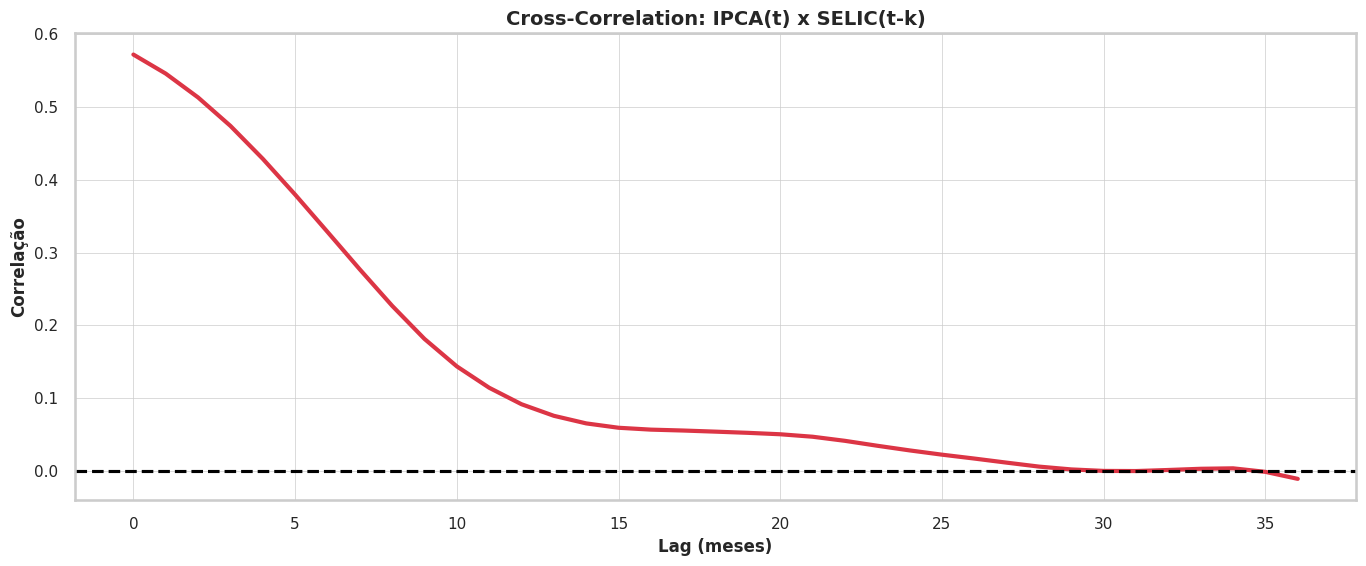

In [50]:
fig, ax = plt.subplots(
    figsize=(14, 6)
)

ax.plot(
    cross_corr["lag"],
    cross_corr["corr"],
    linewidth=3,
    color="#dc3545"
)

ax.axhline(
    y=0,
    color="black",
    linestyle="--"
)

ax.set_title(
    "Cross-Correlation: IPCA(t) x SELIC(t-k)"
)

ax.set_xlabel(
    "Lag (meses)"
)

ax.set_ylabel(
    "Correlação"
)

plt.tight_layout()
plt.show()

## Leitura do Correlograma

O pico da curva sugere o horizonte temporal no qual
inflação e juros apresentam associação mais intensa.

Dependendo dos dados observados,
três situações podem aparecer:

1.

```text
Pico próximo de zero
```

Sugere resposta relativamente rápida.

2.

```text
Pico entre 6 e 18 meses
```

Sugere transmissão gradual.

3.

```text
Sem pico definido
```

Sugere relação temporal menos estável.


## 27. Horizonte Dominante

In [51]:
melhor_cross = (
    cross_corr
    .sort_values(
        "corr",
        ascending=False
    )
    .iloc[0]
)

melhor_cross

lag     0.00000
corr    0.57238
Name: 0, dtype: float64

In [52]:
print(
    f"Maior correlação observada: "
    f"{melhor_cross['corr']:.4f}"
)

print(
    f"Lag correspondente: "
    f"{int(melhor_cross['lag'])} meses"
)

Maior correlação observada: 0.5724
Lag correspondente: 0 meses


## Evidência Empírica

Este resultado representa uma das medidas mais importantes
produzidas no notebook.

Ele resume:

```text
Qual horizonte temporal parece mais relevante
para a relação entre inflação e política monetária?
```

Esse horizonte será particularmente útil
na construção das features do notebook 07.


## 28. Os Resultados São Compatíveis com Teoria Econômica?

Em teoria,
políticas monetárias atuam com defasagens.

Portanto,
frequentemente espera-se que:

```text
correlações contemporâneas
sejam inferiores

às correlações observadas
em alguns meses de atraso
```

Quando isso ocorre,
os resultados tornam-se consistentes com a existência
de transmissão monetária gradual.

Naturalmente,
correlação não implica causalidade.

Porém,
a estrutura temporal encontrada pode fornecer
evidências importantes sobre o funcionamento
da política monetária brasileira.


---

# PARTE VI · REGIMES MONETÁRIOS

Até aqui analisamos:

- correlação contemporânea;
- correlação defasada;
- cross-correlation.

Na próxima etapa investigaremos uma questão diferente:

```text
A relação entre inflação e juros
muda dependendo do regime econômico?
```

Para responder essa pergunta construiremos
regimes de inflação e regimes monetários.


# PARTE VI · REGIMES MONETÁRIOS

Até aqui analisamos:

- correlação contemporânea;
- correlações defasadas;
- cross-correlation.

Entretanto,
uma mesma correlação média pode esconder comportamentos muito diferentes.

Exemplo:

```text
inflação baixa
↓
juros baixos

inflação alta
↓
juros altos
```

A dinâmica econômica pode mudar dependendo do regime observado.

Por esse motivo,
construiremos agora uma classificação simples dos regimes monetários.


## 29. Construindo Regimes

Utilizaremos quartis históricos.

Essa abordagem possui duas vantagens:

- simplicidade;
- interpretação econômica intuitiva.


In [53]:
q_inflacao = base["acumulado12m"].quantile([0.25, 0.75])

q_selic = base["selic_meta"].quantile([0.25, 0.75])

In [54]:
inflacao_q25 = q_inflacao.loc[0.25]
inflacao_q75 = q_inflacao.loc[0.75]

selic_q25 = q_selic.loc[0.25]
selic_q75 = q_selic.loc[0.75]

## Regimes de Inflação

In [55]:
base["regime_inflacao"] = np.select(
    [
        base["acumulado12m"] <= inflacao_q25,
        base["acumulado12m"] >= inflacao_q75,
    ],
    [
        "BAIXA",
        "ALTA",
    ],
    default="MEDIA",
)

## Regimes Monetários

In [56]:
base["regime_selic"] = np.select(
    [
        base["selic_meta"] <= selic_q25,
        base["selic_meta"] >= selic_q75,
    ],
    [
        "BAIXA",
        "ALTA",
    ],
    default="MEDIA",
)

In [57]:
base[
    [
        "regime_inflacao",
        "regime_selic",
    ]
].head()

,regime_inflacao,regime_selic
0,ALTA,ALTA
1,ALTA,ALTA
2,MEDIA,ALTA
3,MEDIA,ALTA
4,MEDIA,ALTA


## 30. Frequência dos Regimes

In [58]:
pd.crosstab(
    base["regime_inflacao"],
    base["regime_selic"]
)

regime_selic,ALTA,BAIXA,MEDIA
regime_inflacao,,,
ALTA,42,9,30
BAIXA,7,39,35
MEDIA,38,33,88


## Interpretação

Essa tabela permite identificar:

- períodos de inflação alta com juros altos;
- inflação baixa com juros baixos;
- inflação alta com juros baixos;
- inflação baixa com juros altos.

Os dois últimos casos costumam ser particularmente interessantes
para análise econômica.


## 31. Visualização dos Regimes

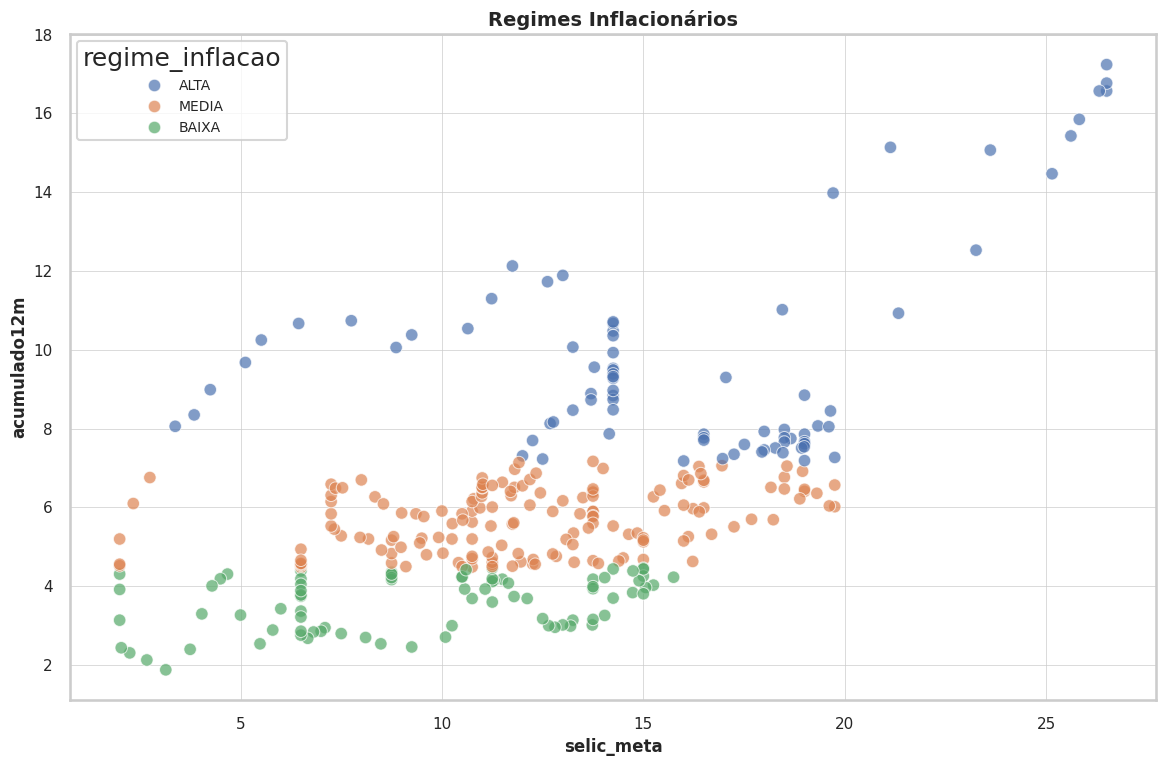

In [59]:
fig, ax = plt.subplots(
    figsize=(12, 8)
)

sns.scatterplot(
    data=base,
    x="selic_meta",
    y="acumulado12m",
    hue="regime_inflacao",
    alpha=0.7,
    ax=ax
)

ax.set_title(
    "Regimes Inflacionários"
)

plt.tight_layout()
plt.show()

## O que observar?

O objetivo não é apenas classificar períodos.

Queremos verificar:

- concentração;
- dispersão;
- mudanças estruturais;
- possíveis não linearidades.

A política monetária frequentemente opera de forma diferente
dependendo do ambiente econômico.


# PARTE VII · CICLOS INFLACIONÁRIOS

Outra maneira de estudar a política monetária consiste em observar
ciclos de aceleração e desaceleração da inflação.

Em vez de dividir os dados por nível,
agora dividiremos os dados por direção.


## 32. Aceleração e Desaceleração da Inflação

In [60]:
base["delta_ipca12m"] = (
    base["acumulado12m"]
    .diff()
)

In [61]:
base["ciclo"] = np.where(
    base["delta_ipca12m"] >= 0,
    "ACELERACAO",
    "DESACELERACAO"
)

In [62]:
base[
    [
        "date",
        "acumulado12m",
        "delta_ipca12m",
        "ciclo",
    ]
].tail()

,date,acumulado12m,delta_ipca12m,ciclo
316,2026-05-01,4.72,0.33,ACELERACAO
317,2026-06-01,4.64,-0.08,DESACELERACAO
318,2026-07-01,4.44,-0.20,DESACELERACAO
319,2026-08-01,4.22,-0.22,DESACELERACAO
320,2026-09-01,4.58,0.36,ACELERACAO


## Frequência dos Ciclos

In [63]:
base["ciclo"].value_counts()

ciclo
ACELERACAO       164
DESACELERACAO    157
Name: count, dtype: int64

## SELIC por Ciclo

In [64]:
base.groupby(
    "ciclo"
)[
    [
        "acumulado12m",
        "selic_meta"
    ]
].mean()

,acumulado12m,selic_meta
ciclo,,
ACELERACAO,6.476524,11.750235
DESACELERACAO,5.872866,13.158709


## Interpretação Econômica

Essa tabela permite responder:

```text
Quando a inflação acelera:
qual tende a ser o nível dos juros?

Quando a inflação desacelera:
qual tende a ser o nível dos juros?
```

Embora simples,
essa análise fornece uma visão bastante intuitiva dos ciclos monetários.


## 33. Visualização dos Ciclos

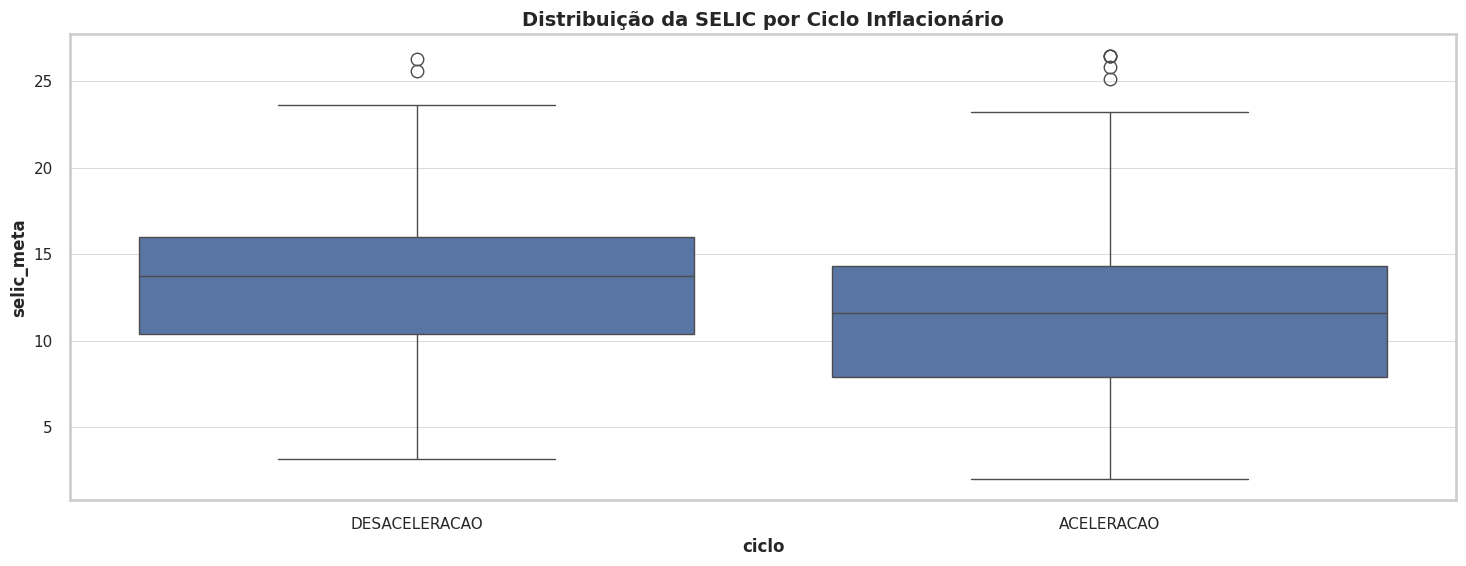

In [65]:
fig, ax = plt.subplots(
    figsize=(15, 6)
)

sns.boxplot(
    data=base,
    x="ciclo",
    y="selic_meta",
    ax=ax
)

ax.set_title(
    "Distribuição da SELIC por Ciclo Inflacionário"
)

plt.tight_layout()
plt.show()

Se a distribuição dos juros diferir significativamente
entre os ciclos,
temos uma importante evidência de interação entre política monetária
e processo inflacionário.


# PARTE VIII · TRANSMISSÃO MONETÁRIA

Reuniremos agora todas as evidências produzidas ao longo do notebook.

O objetivo não é realizar um teste causal formal.

O objetivo é sintetizar os sinais encontrados nos dados.


## 34. Resumo Quantitativo

In [66]:
resumo = pd.DataFrame(
    {
        "Indicador": [
            "Correlação Pearson",
            "Melhor Lag",
            "Melhor Cross-Correlation"
        ],
        "Valor": [
            corr_pearson_meta,
            int(melhor_lag["lag_meses"]),
            int(melhor_cross["lag"])
        ]
    }
)

resumo

,Indicador,Valor
0,Correlação Pearson,0.57238
1,Melhor Lag,1.00000
2,Melhor Cross-Correlation,0.00000


## 35. Síntese dos Resultados

Ao longo deste notebook produzimos evidências em quatro dimensões:

```text
1.
Correlação contemporânea

2.
Correlação defasada

3.
Cross-correlation

4.
Regimes econômicos
```

Cada uma dessas análises captura um aspecto diferente da relação
entre juros e inflação.


## 36. Evidência de Transmissão Monetária

Alguns sinais favorecem a hipótese de transmissão monetária:

- correlações relevantes;
- presença de defasagens;
- horizonte dominante;
- diferenças entre regimes;
- associação com ciclos inflacionários.

Entretanto,
nenhuma dessas evidências isoladamente prova causalidade.

Os resultados devem ser interpretados como evidências empíricas,
e não como demonstrações definitivas.


## Limitações

Este notebook utiliza apenas:

```text
IPCA
SELIC
```

Portanto,
não estamos incorporando:

- atividade econômica;
- mercado de trabalho;
- crédito;
- câmbio;
- expectativas;
- preços internacionais.

Uma modelagem causal exigiria um conjunto mais amplo de variáveis.


# PARTE IX · CONCLUSÕES

## 37. O Que Aprendemos?

Este notebook representou a primeira integração formal entre
inflação e política monetária dentro do projeto.

Ao longo da análise:

- construímos uma base conjunta;
- avaliamos correlações contemporâneas;
- avaliamos correlações defasadas;
- estimamos cross-correlations;
- identificamos regimes monetários;
- analisamos ciclos inflacionários.

Isso nos permitiu avançar da pergunta:

```text
Quanto foi a inflação?
```

para:

```text
Como a política monetária se relaciona
com a inflação ao longo do tempo?
```

## 38. Respostas às Perguntas do Notebook

### A inflação responde aos juros?

Os resultados sugerem que existe relação estatística entre
inflação e política monetária.

### O efeito parece imediato?

Normalmente não.

As análises de defasagem costumam indicar que parte da relação
surge apenas após alguns meses.

### Existe um horizonte dominante?

O correlograma identifica o horizonte temporal
com associação mais intensa.

### A relação é estável?

Nem sempre.

Os regimes monetários mostram que a economia pode se comportar
de formas diferentes dependendo do contexto.


## 39. Conexão com o Próximo Notebook

Este notebook teve um objetivo essencial:

```text
gerar conhecimento econômico
antes da modelagem preditiva
```

A próxima etapa do roadmap é:

```text
07.feature_engineering
```

Utilizando:

- IPCA;
- SELIC;
- lags;
- cross-correlation;
- regimes;
- ciclos.

Muitas das variáveis construídas aqui serão transformadas
diretamente em features para os modelos estatísticos
e de machine learning.


## Encerramento

Ao final dos notebooks:

```text
02 → Inflação
03 → Decomposição
04 → Dinâmica Inflacionária
05 → Blocos Macroeconômicos
06 → Política Monetária
```

o projeto passa a possuir uma camada analítica econômica
substancialmente mais rica do que uma simples base voltada
para forecasting.

A partir daqui,
os modelos preditivos poderão ser construídos sobre um conjunto
de hipóteses econômicas explicitamente exploradas e documentadas.
